<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Windows Registry Hives](https://github.com/Query-farm/vgi-reghive)

Parse offline Windows Registry hive files into SQL rows for forensics, with transaction-log replay and deleted-key recovery.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-reghive/blob/main/notebooks/02_a_missing_key_needs_a_search_scope.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-reghive/blob/main/notebooks/README.md)


## 02 · A missing key needs a search scope

**What does an empty Registry lookup actually tell us?** A reference list tells us
where to look; it does not prove those keys exist. We will check four SOFTWARE
locations, retrieve one present key at three levels of detail, and then deliberately
ask for an absent key. Missing results stay distinct from keys containing no values.

The single SOFTWARE hive is a synthetic test fixture, identical to the first
notebook's input. Its path strings are inert example text. We do not execute values
or inspect a live Windows installation. The file has a clean header and no supplied
transaction logs; this example studies allocated content, not deletion history.

### Choose one reference key

`TARGET_KEY="Run"` selects a key that exists in this fixture. The experiment uses
`"RunOnce"`, a reference key that is absent. Change the parameter, then restart and
run all. The bytes and four-key reference population remain fixed.

In [1]:
TARGET_KEY = "Run"  # "Run" or "RunOnce"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.14":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.14"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme, prose
from IPython.display import display

check_runtime()
prepare("reghive")
import reghive_example as example

if TARGET_KEY not in {"Run", "RunOnce"}:
    raise ValueError("TARGET_KEY must be Run or RunOnce.")
theme()
session = connect(globals())

### Connect to the released parser

The native `v0.4.0` release runs through VGI without a Rust build. The shared setup
retrieves the small, checksum-verified synthetic fixtures when this notebook is
opened on its own. All data operations below remain visible SQL.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'reghive' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-reghive@v0.4.0');
CREATE TABLE fixture AS SELECT content FROM read_blob('fixtures/software.hve');
SELECT (reghive.main.well_formed(content)).ok AS header_ok,
       (reghive.main.hive_info(content)).is_dirty AS dirty_header FROM fixture;

,header_ok,dirty_header
0,True,False


### Start with a reference population, then test presence

`forensic_keys` supplies four SOFTWARE locations and their context. `key_info`
probes each path and returns metadata only. We keep every reference row, including
NULL lookups. The final path component is a display label; the exact returned path
is passed to the parser, without adding or removing its separators.

A reference category or technique identifies a place worth reviewing; a match is
not a verdict about a program, account or machine. The fixed last-write timestamps
belong to the fixture and do not establish when a value executed or was deleted.

In [5]:
%%sql
CREATE TABLE reference_scope AS
SELECT key_path, split_part(key_path,chr(92),-1) AS key_label,
       category, description, mitre_technique,
       reghive.main.key_info(content,key_path) AS info
FROM reghive.main.forensic_keys CROSS JOIN fixture WHERE hive='SOFTWARE';
CREATE TABLE selected_reference AS
 SELECT key_path FROM reference_scope WHERE key_label='{{ TARGET_KEY }}';
SELECT key_label,category,info IS NOT NULL AS present,
       info.value_count AS value_count,info.last_write AS key_last_write
FROM reference_scope ORDER BY key_label;

,key_label,category,present,value_count,key_last_write
0,Run,Persistence,True,5,2019-12-31 19:00:00-05:00
1,RunOnce,Persistence,False,<NA>,NaT
2,Uninstall,Configuration,False,<NA>,NaT
3,Winlogon,Persistence,False,<NA>,NaT


In [6]:
%%sql reference <<
SELECT key_label,info IS NOT NULL AS present,info.value_count AS value_count
FROM reference_scope ORDER BY key_label;

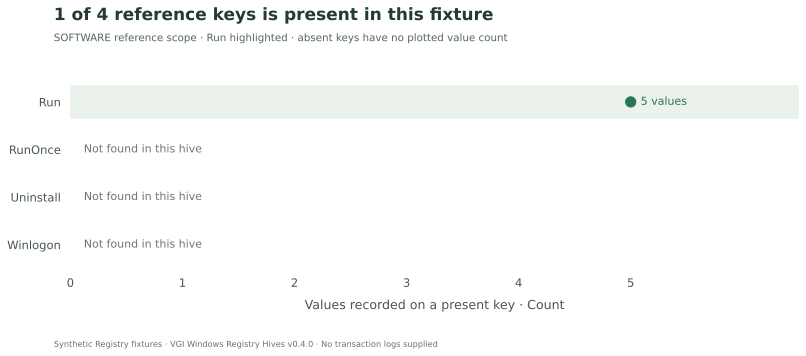

**1/4 reference keys are present** in this file. An absent key has NULL metadata; it is not a present key with a zero value count. The selected **Run** key determines the next lookups, while this reference audit stays fixed.

In [7]:
example.plot_lookup_scope(reference, TARGET_KEY)
prose(f"**{int(reference.present.sum())}/{len(reference)} reference keys are present** in this file. "
      "An absent key has NULL metadata; it is not a present key with a zero value count. "
      f"The selected **{TARGET_KEY}** key determines the next lookups, while this reference audit stays fixed.")

### Compare a key, one value, and a subtree

`hive_key` returns the key with its values nested inside. `hive_value` returns the
named `Updater` value. `hive_subtree` emits relational rows, so we can inspect types,
lossless raw bytes and provenance. It takes constant arguments. The short Python cell below
formats the already-loaded bytes and selected reference path as SQL literals;
the query stays readable and the binary data is not printed. Materialized tables
carry the data between SQL cells.

We explicitly disable log replay and deleted recovery on the subtree. The scalar
lookups have no recovery option, so we reconcile them only for this known live Run
key; that agreement does not prove equivalent scope on arbitrary damaged hives.
Only rows with `value_type IS NOT NULL` count as values.

In [8]:
%%sql
CREATE TABLE selected_key AS
SELECT reghive.main.hive_key(content,key_path) AS key_record FROM fixture CROSS JOIN selected_reference;
CREATE TABLE selected_value AS
SELECT reghive.main.hive_value(content,key_path,'Updater') AS value_record FROM fixture CROSS JOIN selected_reference;
SELECT '{{ TARGET_KEY }}' AS selected_key,key_record IS NOT NULL AS key_present,
       key_record.value_count AS declared_values,len(key_record.values) AS returned_nested_values,
       value_record.value_type AS updater_type,value_record.value_data AS updater_text,
       octet_length(value_record.value_raw) AS updater_raw_bytes
FROM selected_key CROSS JOIN selected_value;

,selected_key,key_present,declared_values,returned_nested_values,updater_type,updater_text,updater_raw_bytes
0,Run,True,5,5,REG_SZ,C:\Windows\evil.exe,40


In [9]:
hive_hex = con.execute("SELECT hex(content) FROM fixture").fetchone()[0]
selected_path = con.execute("SELECT key_path FROM selected_reference").fetchone()[0]
selected_path_sql = "'" + selected_path.replace("'", "''") + "'"


In [10]:
%%sql
CREATE TABLE selected_subtree AS
SELECT * FROM reghive.main.hive_subtree(
 unhex('{{ hive_hex }}'),{{ selected_path_sql }},
 apply_logs:=false,recover_deleted:=false);
SELECT value_name,value_type,value_data,octet_length(value_raw) AS raw_bytes,
       is_deleted,recovery FROM selected_subtree
WHERE value_type IS NOT NULL ORDER BY value_name;

,value_name,value_type,value_data,raw_bytes,is_deleted,recovery
0,Big,REG_QWORD,18838586676582,8,False,None
1,Blob,REG_BINARY,deadbeef,4,False,None
2,List,REG_MULTI_SZ,alpha\nbeta,24,False,None
3,Start,REG_DWORD,2,4,False,None
4,Updater,REG_SZ,C:\Windows\evil.exe,40,False,None


In [11]:
%%sql lookup_summary <<
SELECT (SELECT key_record IS NOT NULL FROM selected_key) AS key_present,
       (SELECT count(*) FROM selected_subtree WHERE value_type IS NOT NULL) AS returned_values,
       (SELECT value_record IS NOT NULL FROM selected_value) AS named_value_present;

In [12]:
result = lookup_summary.iloc[0]
prose(
    f"**{TARGET_KEY}: {int(result.returned_values)} returned value rows.** "
    + ("The key contains five typed values, including the named Updater value. Its executable-looking string is fixture text, not execution evidence."
       if result.key_present else
       "The key and named value lookups are NULL, and the subtree has no rows. Because the header is known valid and the reference path is explicit, we can report this key was not found in this supplied file. This does not establish that it never existed on a machine.")
)

**Run: 5 returned value rows.** The key contains five typed values, including the named Updater value. Its executable-looking string is fixture text, not execution evidence.

### Reconcile the three representations

The fixture supplies a useful control: Run has five values, while RunOnce is absent.
These assertions compare nested key values, the named value and the subtree bytes;
they do not turn a successful parser round trip into historical proof.

In [13]:
%%sql lookup_checks <<
SELECT 'All four reference paths retained' AS check_name,
       (SELECT count(*)=4 AND count(DISTINCT key_path)=4 FROM reference_scope) AS passed
UNION ALL SELECT 'Absent keys retain NULL counts',
       (SELECT count(*)=3 AND bool_and(info.value_count IS NULL) FROM reference_scope WHERE info IS NULL)
UNION ALL SELECT 'Exactly one reference path is selected',
       (SELECT count(*)=1 FROM selected_reference)
UNION ALL SELECT 'Selected presence follows the fixture',
       (SELECT (key_record IS NOT NULL)=('{{ TARGET_KEY }}'='Run') FROM selected_key)
UNION ALL SELECT 'Selected value count follows the fixture',
       (SELECT count(*)=CASE WHEN '{{ TARGET_KEY }}'='Run' THEN 5 ELSE 0 END FROM selected_subtree WHERE value_type IS NOT NULL)
UNION ALL SELECT 'No recovered rows enter the subtree',
       NOT EXISTS(SELECT 1 FROM selected_subtree WHERE is_deleted)
UNION ALL SELECT 'Key metadata and nested population agree',
       (SELECT key_record IS NULL OR key_record.value_count=len(key_record.values) FROM selected_key)
UNION ALL SELECT 'Key and relational value populations agree',
       (SELECT coalesce(len(key_record.values),0)=(SELECT count(*) FROM selected_subtree WHERE value_type IS NOT NULL) FROM selected_key)
UNION ALL SELECT 'Named lookup and subtree preserve the same bytes',
       (SELECT CASE WHEN value_record IS NULL THEN NOT EXISTS(SELECT 1 FROM selected_subtree WHERE value_name='Updater')
         ELSE value_record.value_raw=(SELECT value_raw FROM selected_subtree WHERE value_name='Updater') END FROM selected_value);

In [14]:
display(lookup_checks)
assert lookup_checks.passed.fillna(False).all(), lookup_checks
prose(f"**All {len(lookup_checks)} checks passed.** The selected scope reconciles; the unchanged reference audit still contains all four candidate locations.")

,check_name,passed
0,All four reference paths retained,True
1,Absent keys retain NULL counts,True
2,Exactly one reference path is selected,True
3,Selected presence follows the fixture,True
4,Selected value count follows the fixture,True
5,No recovered rows enter the subtree,True
6,Key metadata and nested population agree,True
7,Key and relational value populations agree,True
8,Named lookup and subtree preserve the same bytes,True


**All 9 checks passed.** The selected scope reconciles; the unchanged reference audit still contains all four candidate locations.

### Experiment: select RunOnce

Change `TARGET_KEY` from `"Run"` to `"RunOnce"` and run all. Predict that the highlighted
row changes and the selected key/value structures become NULL, with zero subtree
rows. The four-key inventory must remain unchanged: it still contains the present
Run key and three absent reference keys. The evidence bytes did not change.

```sh
uv run --locked vgi-notebooks 02_a_missing_key_needs_a_search_scope.ipynb \
  --parameters '{"TARGET_KEY":"RunOnce"}' --output-dir artifacts/missing-key
```

An empty lookup becomes interpretable only with a valid input, an explicit path and
a known search scope. For deleted content, return to the
[recovery notebook](01_recovery_changes_the_evidence_population.ipynb) and keep its
returned provenance labels rather than merging recovered rows into current values.

In [15]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-reghive](https://github.com/Query-farm/vgi-reghive)